# Đồ án / Thực hành Phân loại ảnh CIFAR-10 bằng các kiến trúc CNN (LeNet, VGG-tiny, Inception-tiny, ResNet-tiny)

Notebook này thực hiện quy trình huấn luyện, kiểm thử và so sánh **8 cấu hình mô hình** (`E0–E4` biến thể LeNet và `M1–M3` kiến trúc hiện đại thu gọn) trên bộ dữ liệu **CIFAR-10** (`40,000` Train / `5,000` Validation / `5,000` Test).

## Cell 1: Import thư viện & Cấu hình hệ thống
Thiết lập seed tái lập kết quả, đường dẫn lưu trữ (`DATA_ROOT`, `OUTPUT_ROOT`, `CACHE_DIR`, `PLOT_DIR`) và siêu tham số huấn luyện.

In [11]:
import os
import time
import copy
import pickle
import random
import shutil
import zipfile
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

SEED = 42
QUICK = False                     # False = chạy 15 Epochs; True = chạy nhanh 2 Epochs để kiểm tra
SAMPLES_PER_CLASS = None          # None = dùng toàn bộ dữ liệu hợp lệ; đặt số nhỏ (vd: 200) để test nhanh
SHOW_PLOTS_INLINE = True          # True = hiện hình trực tiếp dưới cell giống Colab + vẫn lưu file .png

BASE_DIR = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
RUN_TAG = "script1"               # Trỏ đúng vào thư mục cache/output của script1 để lấy kết quả cũ

DATA_ROOT = BASE_DIR / "data"
OUTPUT_ROOT = BASE_DIR / "outputs" / RUN_TAG
CACHE_DIR = OUTPUT_ROOT / "exp_cache"
PLOT_DIR = OUTPUT_ROOT / "plots"

CACHE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

ZIP_PATH = DATA_ROOT / "cifar-10.zip"

BATCH_SIZE = 128
LR = 1e-3
IN_CHANNELS = 3
NUM_CLASSES = 10
EPOCHS = 2 if QUICK else 15

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

CIFAR10_CLASSES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CIFAR10_CLASSES)}


def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


seed_all()
torch.set_num_threads(min(4, os.cpu_count() or 2))

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
print(f"PyTorch {torch.__version__} | Run = {RUN_TAG} | Device = {DEVICE} (AMP={USE_AMP}) | Seed = {SEED}")
print(f"Cache dir: {CACHE_DIR.resolve()} | Số file .pkl tìm thấy: {len(list(CACHE_DIR.glob('*.pkl')))}")

PyTorch 2.15.0+cpu | Run = script1 | Device = cpu (AMP=False) | Seed = 42
Cache dir: D:\WelcomeScreen\outputs\script1\exp_cache | Số file .pkl tìm thấy: 16


## Cell 2: Tìm đường dẫn dữ liệu & định nghĩa Dataset
Tự động tìm hoặc giải nén `cifar-10.zip` (`train.7z` / `test.7z`) và định nghĩa lớp `Cifar10LabeledDataset`, `Cifar10UnlabeledDataset`.

In [12]:
def find_label_file(folder: Path):
    for candidate in (folder / "trainLabels.csv", folder / "trainLabels"):
        if candidate.is_file():
            return candidate
    if folder.is_dir():
        for p in folder.iterdir():
            if p.is_file() and p.name.startswith("trainLabels"):
                return p
    return None


def find_train_images_dir(base_dir: Path):
    for candidate in (base_dir / "train", base_dir / "train" / "train", base_dir / "train_imgs"):
        if candidate.is_dir() and any(candidate.glob("*.png")):
            return candidate
    if base_dir.is_dir():
        for p in base_dir.rglob("*.png"):
            rel_parts = p.relative_to(base_dir).parts
            if "test" not in rel_parts:
                return p.parent
    return None


def find_test_images_dir(base_dir: Path):
    for candidate in (base_dir / "test", base_dir / "test" / "test", base_dir / "test_imgs"):
        if candidate.is_dir() and any(candidate.glob("*.png")):
            return candidate
    return base_dir / "test"


def prepare_data_paths(data_root: Path, zip_path: Path):
    data_root.mkdir(parents=True, exist_ok=True)
    labels_file = find_label_file(data_root)
    train_dir = find_train_images_dir(data_root)

    if labels_file is not None and train_dir is not None:
        return labels_file, train_dir

    if not zip_path.is_file():
        raise FileNotFoundError(
            f"Không tìm thấy dữ liệu giải nén trong '{data_root}' và cũng không có file zip tại '{zip_path}'."
        )

    print("Đang giải nén file zip...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(data_root)

    train_7z = data_root / "train.7z"
    if train_7z.is_file() and find_train_images_dir(data_root) is None:
        extract_dir = data_root / "train"
        extract_dir.mkdir(parents=True, exist_ok=True)
        if shutil.which("7z") is not None:
            print("Đang giải nén train.7z bằng 7z...")
            subprocess.run(["7z", "x", "-y", str(train_7z), f"-o{extract_dir}"], check=True)
        else:
            try:
                import py7zr
                print("Đang giải nén train.7z bằng py7zr...")
                with py7zr.SevenZipFile(train_7z, mode="r") as z:
                    z.extractall(path=extract_dir)
            except ImportError as e:
                raise RuntimeError("Thiếu '7z' trong PATH và chưa cài 'py7zr'. Hãy cài 7-Zip hoặc chạy: pip install py7zr") from e

    test_7z = data_root / "test.7z"
    if test_7z.is_file() and not any((data_root / "test").glob("*.png")):
        test_extract_dir = data_root / "test"
        test_extract_dir.mkdir(parents=True, exist_ok=True)
        if shutil.which("7z") is not None:
            print("Đang giải nén test.7z bằng 7z...")
            subprocess.run(["7z", "x", "-y", str(test_7z), f"-o{test_extract_dir}"], check=True)
        else:
            try:
                import py7zr
                print("Đang giải nén test.7z bằng py7zr...")
                with py7zr.SevenZipFile(test_7z, mode="r") as z:
                    z.extractall(path=test_extract_dir)
            except ImportError:
                print("Cảnh báo: Không tìm thấy 7z/py7zr để giải nén test.7z (bỏ qua xuất submission Kaggle).")

    labels_file = find_label_file(data_root)
    train_dir = find_train_images_dir(data_root)
    if labels_file is None or train_dir is None:
        raise FileNotFoundError(f"Sau khi giải nén vẫn thiếu trainLabels hoặc ảnh *.png trong '{data_root}'.")
    return labels_file, train_dir


class Cifar10LabeledDataset(Dataset):
    def __init__(self, img_dir: Path, df: pd.DataFrame, transform=None):
        self.img_dir = img_dir
        self.ids = df["id"].astype(int).tolist()
        self.labels = [CLASS_TO_IDX[lbl] for lbl in df["label"].tolist()]
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_path = self.img_dir / f"{self.ids[idx]}.png"
        with Image.open(img_path) as image:
            image = image.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(self.labels[idx], dtype=torch.long)


class Cifar10UnlabeledDataset(Dataset):
    def __init__(self, img_dir: Path, ids, transform=None):
        self.img_dir = img_dir
        self.ids = list(ids)
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = int(self.ids[idx])
        img_path = self.img_dir / f"{img_id}.png"
        with Image.open(img_path) as image:
            image = image.convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, img_id

## Cell 3: Nạp dữ liệu, chia Train/Val/Test & tạo DataLoader
Chia phân tầng (`stratify`) theo tỷ lệ **80% Train / 10% Validation / 10% Test**, áp dụng chuẩn hóa `(MEAN, STD)` và Data Augmentation.

In [13]:
labels_path, train_img_dir = prepare_data_paths(DATA_ROOT, ZIP_PATH)
test_img_dir = find_test_images_dir(DATA_ROOT)
print(f"DATA_ROOT = {DATA_ROOT} | train_img_dir = {train_img_dir} | labels = {labels_path.name} | EPOCHS = {EPOCHS}")

labels_df = pd.read_csv(labels_path)
if "label" not in labels_df.columns and "Label" in labels_df.columns:
    labels_df = labels_df.rename(columns={"Label": "label"})

existing_ids = {int(p.stem) for p in train_img_dir.glob("*.png") if p.stem.isdigit()}
labels_df["id"] = labels_df["id"].astype(int)
labels_df = labels_df[labels_df["id"].isin(existing_ids)].reset_index(drop=True)
if len(labels_df) == 0:
    raise FileNotFoundError(f"Không tìm thấy ảnh hợp lệ khớp nhãn trong {train_img_dir}")

if SAMPLES_PER_CLASS is not None:
    sampled_parts = []
    for _, grp in labels_df.groupby("label"):
        n_take = min(len(grp), SAMPLES_PER_CLASS)
        sampled_parts.append(grp.sample(n=n_take, random_state=SEED))
    labels_df = pd.concat(sampled_parts, ignore_index=True)

train_df, temp_df = train_test_split(
    labels_df, test_size=0.2, random_state=SEED, stratify=labels_df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.5, random_state=SEED, stratify=temp_df["label"]
)

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.07, 0.07), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

num_workers = 2 if DEVICE.type == "cuda" else 0
pin = (DEVICE.type == "cuda")

train_clean_ds = Cifar10LabeledDataset(train_img_dir, train_df, eval_transform)
train_plain_ds = Cifar10LabeledDataset(train_img_dir, train_df, eval_transform)
train_aug_ds = Cifar10LabeledDataset(train_img_dir, train_df, aug_transform)
val_ds = Cifar10LabeledDataset(train_img_dir, val_df, eval_transform)
test_ds = Cifar10LabeledDataset(train_img_dir, test_df, eval_transform)

train_clean_loader = DataLoader(train_clean_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin)
train_plain_loader = DataLoader(train_plain_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers, pin_memory=pin)
train_aug_loader = DataLoader(train_aug_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=num_workers, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=num_workers, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=num_workers, pin_memory=pin)

loaders = (train_plain_loader, train_aug_loader, train_clean_loader, val_loader)
print(f"Train/Val/Test: {len(train_df)}/{len(val_df)}/{len(test_df)} | Classes: {NUM_CLASSES}")

DATA_ROOT = D:\WelcomeScreen\data | train_img_dir = D:\WelcomeScreen\data\train\train | labels = trainLabels.csv | EPOCHS = 15
Train/Val/Test: 40000/5000/5000 | Classes: 10


## Cell 4: Định nghĩa các kiến trúc CNN
Xây dựng `LeNet` (tùy biến Tanh/ReLU, AvgPool/MaxPool, BatchNorm, Dropout), `VGGTiny`, `InceptionTiny` và `ResNetTiny`.

In [14]:
class LeNet(nn.Module):
    def __init__(self, activation="tanh", pool="avg", batchnorm=False, dropout=0.0, n_classes=10):
        super().__init__()
        make_act = nn.Tanh if activation == "tanh" else nn.ReLU
        make_pool = nn.AvgPool2d if pool == "avg" else nn.MaxPool2d
        self.features = nn.Sequential(
            nn.Conv2d(3, 6, kernel_size=5),
            nn.BatchNorm2d(6) if batchnorm else nn.Identity(),
            make_act(),
            make_pool(2),
            nn.Conv2d(6, 16, kernel_size=5),
            nn.BatchNorm2d(16) if batchnorm else nn.Identity(),
            make_act(),
            make_pool(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), make_act(), nn.Dropout(dropout),
            nn.Linear(120, 84), make_act(), nn.Dropout(dropout),
            nn.Linear(84, n_classes),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def vgg_block(cin, cout, nconv=2):
    layers = []
    for j in range(nconv):
        layers += [
            nn.Conv2d(cin if j == 0 else cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(),
        ]
    return nn.Sequential(*layers, nn.MaxPool2d(2))


class VGGTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(vgg_block(3, 16), vgg_block(16, 32), vgg_block(32, 64))
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(),
            nn.Linear(64, 64), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(64, n_classes),
        )

    def forward(self, x):
        return self.head(self.features(x))


class InceptionBlock(nn.Module):
    def __init__(self, cin, branch_channels):
        super().__init__()
        c = branch_channels

        def cbr(a, b, k, p=0):
            return [nn.Conv2d(a, b, k, padding=p, bias=False), nn.BatchNorm2d(b), nn.ReLU()]

        self.b1 = nn.Sequential(*cbr(cin, c, 1))
        self.b3 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 3, p=1))
        self.b5 = nn.Sequential(*cbr(cin, c, 1), *cbr(c, c, 5, p=2))
        self.bp = nn.Sequential(nn.MaxPool2d(3, stride=1, padding=1), *cbr(cin, c, 1))

    def forward(self, x):
        return torch.cat([self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1)


class InceptionTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            InceptionBlock(16, 8), nn.MaxPool2d(2),
            InceptionBlock(32, 16), nn.MaxPool2d(2),
            InceptionBlock(64, 16),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.25), nn.Linear(64, n_classes)
        )

    def forward(self, x):
        return self.head(self.features(x))


class ResidualBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.residual = nn.Sequential(
            nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
        )
        self.skip = (
            nn.Identity()
            if cin == cout and stride == 1
            else nn.Sequential(nn.Conv2d(cin, cout, 1, stride=stride, bias=False), nn.BatchNorm2d(cout))
        )
        self.act = nn.ReLU()

    def forward(self, x):
        return self.act(self.residual(x) + self.skip(x))


class ResNetTiny(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        self.blocks = nn.Sequential(
            ResidualBlock(16, 16),
            ResidualBlock(16, 32, stride=2),
            ResidualBlock(32, 32),
            ResidualBlock(32, 64, stride=2),
            ResidualBlock(64, 64),
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.blocks(self.stem(x)))


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Cell 5: Hàm huấn luyện, đánh giá, cache & trực quan hóa
Cài đặt vòng lặp huấn luyện (`fit_model`), lưu checkpoint theo `val_loss` tốt nhất, cơ chế cache `.pkl` và các hàm vẽ Learning Curves, Confusion Matrix, Top Misclassified.

In [15]:
criterion = nn.CrossEntropyLoss()


def safe_filename(name: str) -> str:
    return "".join(ch if ch.isalnum() or ch in ("-", "_") else "_" for ch in name)


def train_one_epoch(model, dataloader, optimizer, criterion, device, scaler=None):
    model.train()
    use_amp = scaler is not None and scaler.is_enabled()
    total_loss, n_correct, n_samples = 0.0, 0, 0
    for x, y in dataloader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
            loss = criterion(logits.float(), y)
        if use_amp:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()
        bs = y.size(0)
        total_loss += loss.item() * bs
        n_correct += (logits.argmax(dim=1) == y).sum().item()
        n_samples += bs
    return {"loss": total_loss / max(1, n_samples), "accuracy": n_correct / max(1, n_samples), "n_samples": n_samples}


@torch.inference_mode()
def evaluate(model, dataloader, criterion, device, return_predictions=False):
    model.eval()
    use_amp = device.type == "cuda"
    total_loss, n_correct, n_samples = 0.0, 0, 0
    y_true, y_pred = [], []
    for x, y in dataloader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            logits = model(x)
            loss = criterion(logits.float(), y)
        preds = logits.argmax(dim=1)
        bs = y.size(0)
        total_loss += loss.item() * bs
        n_correct += (preds == y).sum().item()
        n_samples += bs
        if return_predictions:
            y_true.extend(y.cpu().tolist())
            y_pred.extend(preds.cpu().tolist())

    metrics = {"loss": total_loss / max(1, n_samples), "accuracy": n_correct / max(1, n_samples), "n_samples": n_samples}
    if return_predictions:
        metrics["y_true"] = np.asarray(y_true, dtype=np.int64)
        metrics["y_pred"] = np.asarray(y_pred, dtype=np.int64)
    return metrics


def test_model(model, dataloader, criterion, device, class_names):
    raw = evaluate(model, dataloader, criterion, device, return_predictions=True)
    labels = list(range(len(class_names)))
    cm = confusion_matrix(raw["y_true"], raw["y_pred"], labels=labels)
    report = classification_report(
        raw["y_true"], raw["y_pred"], labels=labels, target_names=class_names, zero_division=0
    )
    return {
        "loss": raw["loss"],
        "accuracy": raw["accuracy"],
        "n_samples": raw["n_samples"],
        "y_true": raw["y_true"],
        "y_pred": raw["y_pred"],
        "confusion_matrix": cm,
        "classification_report": report,
    }


def fit_model(model, train_loader, train_monitor_loader, val_loader, optimizer, criterion, device, epochs, scaler=None):
    history = []
    best_val_loss, best_state, best_epoch = float("inf"), None, 0
    print("epoch | opt_loss | train_loss | train_acc | val_loss | val_acc | time | best")
    print("-" * 86)
    for epoch in range(1, epochs + 1):
        t_ep = time.perf_counter()
        opt = train_one_epoch(model, train_loader, optimizer, criterion, device, scaler)
        tr = evaluate(model, train_monitor_loader, criterion, device)
        va = evaluate(model, val_loader, criterion, device)
        dt = time.perf_counter() - t_ep

        history.append({
            "epoch": epoch,
            "opt_loss": opt["loss"],
            "train_loss": tr["loss"],
            "train_acc": tr["accuracy"],
            "val_loss": va["loss"],
            "val_acc": va["accuracy"],
        })
        improved = va["loss"] < best_val_loss
        if improved:
            best_val_loss = va["loss"]
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        print(
            f"{epoch:02d}/{epochs:02d} | {opt['loss']:.4f}   | {tr['loss']:.4f}     | "
            f"{tr['accuracy']:.2%}  | {va['loss']:.4f}   | {va['accuracy']:.2%}  | {dt:4.1f}s | {'*' if improved else ''}",
            flush=True,
        )

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch


def _finalize_figure(fig, out_path: Path, show_inline: bool):
    fig.savefig(out_path, dpi=135, bbox_inches="tight")
    if show_inline:
        plt.show()
    plt.close(fig)


def plot_single_run(name, history, show_inline=SHOW_PLOTS_INLINE):
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
    axes[0].plot(history["epoch"], history["train_acc"] * 100, label="Train sạch")
    axes[0].plot(history["epoch"], history["val_acc"] * 100, label="Validation")
    axes[1].plot(history["epoch"], history["train_loss"], label="Train sạch")
    axes[1].plot(history["epoch"], history["val_loss"], label="Validation")
    axes[0].set(xlabel="Epoch", ylabel="Accuracy (%)", title="Accuracy")
    axes[1].set(xlabel="Epoch", ylabel="Cross-entropy loss", title="Loss")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"Learning curves: {name}", weight="bold")
    plt.tight_layout()
    out_img = PLOT_DIR / f"{safe_filename(name)}.png"
    _finalize_figure(fig, out_img, show_inline=show_inline)


def plot_summary_comparison(df_res: pd.DataFrame, show_inline=SHOW_PLOTS_INLINE):
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    df_plot = df_res.sort_values(by="val_acc", ascending=True)
    axes[0].barh(df_plot["model"], df_plot["val_acc"] * 100, label="Val Acc (%)")
    axes[0].barh(df_plot["model"], df_plot["train_acc"] * 100, alpha=0.45, label="Train Acc (%)")
    axes[0].set(xlabel="Accuracy (%)", title="So sánh Accuracy giữa các mô hình")
    axes[0].grid(alpha=0.25, axis="x")
    axes[0].legend()

    df_loss = df_res.sort_values(by="val_loss", ascending=False)
    axes[1].barh(df_loss["model"], df_loss["val_loss"], color="#ea580c")
    axes[1].set(xlabel="Validation Loss", title="So sánh Validation Loss (thấp hơn tốt hơn)")
    axes[1].grid(alpha=0.25, axis="x")

    plt.tight_layout()
    out_img = PLOT_DIR / "comparison_summary.png"
    _finalize_figure(fig, out_img, show_inline=show_inline)


@torch.inference_mode()
def plot_top_misclassified(
    model,
    dataset,
    class_names,
    device,
    out_path: Path,
    mean=MEAN,
    std=STD,
    top_k=6,
    batch_size=128,
    show_inline=SHOW_PLOTS_INLINE,
):
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)

    mistakes = []
    global_idx = 0
    mean_t = torch.tensor(mean, device=device).view(1, 3, 1, 1)
    std_t = torch.tensor(std, device=device).view(1, 3, 1, 1)

    for x, y in loader:
        bs = y.size(0)
        x_dev = x.to(device)
        probs = torch.softmax(model(x_dev), dim=1)
        conf, pred = probs.max(dim=1)

        for i in range(bs):
            true_idx = int(y[i].item())
            pred_idx = int(pred[i].item())
            if pred_idx != true_idx:
                img_vis = (x_dev[i].unsqueeze(0) * std_t + mean_t).clamp(0.0, 1.0)
                img_np = img_vis.squeeze(0).permute(1, 2, 0).cpu().numpy()
                mistakes.append({
                    "idx": global_idx,
                    "img": img_np,
                    "true": class_names[true_idx],
                    "pred": class_names[pred_idx],
                    "conf": float(conf[i].item()),
                    "p_true": float(probs[i, true_idx].item()),
                })
            global_idx += 1

    if not mistakes:
        print("Không có mẫu nào dự đoán sai để vẽ lưới lỗi.")
        return

    mistakes.sort(key=lambda item: item["conf"], reverse=True)
    items = mistakes[:top_k]

    cols = 3
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4.2 * cols, 3.8 * rows))
    axes = np.atleast_1d(axes).ravel()

    for ax, item in zip(axes, items):
        ax.imshow(item["img"])
        ax.axis("off")
        ax.set_title(
            f"#{item['idx']} Thật: {item['true']} -> Dự đoán: {item['pred']}\n"
            f"Confidence: {item['conf']:.1%} | P(nhãn thật): {item['p_true']:.1%}",
            color="#b91c1c",
            fontsize=9.5,
        )

    for ax in axes[len(items):]:
        ax.axis("off")

    plt.tight_layout()
    _finalize_figure(fig, out_path, show_inline=show_inline)
    print(f"Đã lưu ảnh phân tích ca dự đoán sai vào: {out_path}")


def run_experiment(
    name,
    model_factory,
    loaders,
    use_aug=False,
    wd=0.0,
    epochs=EPOCHS,
    seed=SEED,
    samples_per_class=SAMPLES_PER_CLASS,
    show_inline=SHOW_PLOTS_INLINE,
):
    train_plain_loader, train_aug_loader, train_clean_loader, val_loader = loaders
    sample_tag = "full" if samples_per_class is None else f"spc{samples_per_class}"
    hp_tag = "" if (LR == 1e-3 and BATCH_SIZE == 128) else f"_lr{LR:g}_bs{BATCH_SIZE}"
    cache_path = CACHE_DIR / f"{safe_filename(name)}_ep{epochs}_{sample_tag}_wd{wd:g}_aug{int(use_aug)}{hp_tag}.pkl"

    if cache_path.is_file():
        with open(cache_path, "rb") as f:
            cached = pickle.load(f)
        print(f"\n=== {name} [TỪ CACHE: {cache_path.name}] ===")
        print(
            f"CHECKPOINT: epoch {cached['row']['best_epoch']:02d} | "
            f"train_acc={cached['row']['train_acc']:.2%} | val_acc={cached['row']['val_acc']:.2%} | "
            f"val_loss={cached['row']['val_loss']:.4f} | gap={cached['row']['gap']:+.2%}"
        )
        plot_single_run(name, cached["history"], show_inline=show_inline)
        return cached

    seed_all(seed)
    model = model_factory().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=wd)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    dl_train = train_aug_loader if use_aug else train_plain_loader

    t0 = time.perf_counter()
    print(f"\n=== {name} (params={count_params(model):,}, aug={use_aug}, wd={wd:g}, epochs={epochs}) ===")
    model, history, best_epoch = fit_model(
        model, dl_train, train_clean_loader, val_loader, optimizer, criterion, DEVICE, epochs, scaler
    )
    elapsed = time.perf_counter() - t0

    tr = evaluate(model, train_clean_loader, criterion, DEVICE)
    va = evaluate(model, val_loader, criterion, DEVICE)
    row = {
        "model": name,
        "params": count_params(model),
        "best_epoch": best_epoch,
        "train_acc": tr["accuracy"],
        "val_acc": va["accuracy"],
        "val_loss": va["loss"],
        "gap": tr["accuracy"] - va["accuracy"],
        "seconds": round(elapsed, 2),
    }
    print(
        f"CHECKPOINT: epoch {best_epoch:02d} | train_acc={tr['accuracy']:.2%} | "
        f"val_acc={va['accuracy']:.2%} | val_loss={va['loss']:.4f} | gap={row['gap']:+.2%} ({elapsed:.1f}s)"
    )
    plot_single_run(name, history, show_inline=show_inline)

    bundle = {
        "row": row,
        "history": history,
        "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
    }
    with open(cache_path, "wb") as f:
        pickle.dump(bundle, f)
    return bundle


@torch.inference_mode()
def export_kaggle_submission(model, test_dir: Path, eval_transform, out_csv: Path, num_workers: int = 0):
    if not test_dir.exists():
        print(f"Bỏ qua xuất submission vì chưa có thư mục {test_dir}")
        return
    img_files = sorted(
        (p for p in test_dir.glob("*.png") if p.stem.isdigit()),
        key=lambda p: int(p.stem),
    )
    if len(img_files) < 1000:
        print(f"Bỏ qua xuất submission vì thư mục {test_dir} mới có {len(img_files)} ảnh (chưa đầy đủ)")
        return
    ids = [int(p.stem) for p in img_files]
    ds = Cifar10UnlabeledDataset(test_dir, ids, eval_transform)
    loader = DataLoader(ds, batch_size=128, shuffle=False, num_workers=num_workers)
    model.eval()
    preds = []
    for x, _ in loader:
        x = x.to(DEVICE)
        preds.extend(model(x).argmax(dim=1).cpu().tolist())
    sub = pd.DataFrame({
        "id": ids,
        "label": [CIFAR10_CLASSES[idx] for idx in preds],
    })
    sub.to_csv(out_csv, index=False)
    print(f"Đã xuất file nộp bài: {out_csv} ({len(sub)} dòng)")

def plot_confusion_matrix(cm, class_names, title, out_path: Path, show_inline=SHOW_PLOTS_INLINE):
    fig, ax = plt.subplots(figsize=(8.2, 6.8))
    im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set(
        xticks=np.arange(len(class_names)),
        yticks=np.arange(len(class_names)),
        xticklabels=class_names,
        yticklabels=class_names,
        ylabel="Nhãn thật (True)",
        xlabel="Nhãn dự đoán (Predicted)",
        title=title,
    )
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right", rotation_mode="anchor")
    thresh = cm.max() / 2.0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, f"{cm[i, j]}",
                ha="center", va="center",
                color="white" if cm[i, j] > thresh else "black",
                fontsize=8.5,
            )
    plt.tight_layout()
    _finalize_figure(fig, out_path, show_inline=show_inline)


## Cell 6: Chạy các thí nghiệm E0–E4 & M1–M3
Huấn luyện/nạp cache 8 mô hình, xuất bảng tổng hợp Validation (`validation_summary.csv`) và biểu đồ so sánh.


=== E0 LeNet Tanh+Avg [TỪ CACHE: E0_LeNet_Tanh_Avg_ep15_full_wd0_aug0.pkl] ===
CHECKPOINT: epoch 11 | train_acc=66.66% | val_acc=58.02% | val_loss=1.2081 | gap=+8.64%


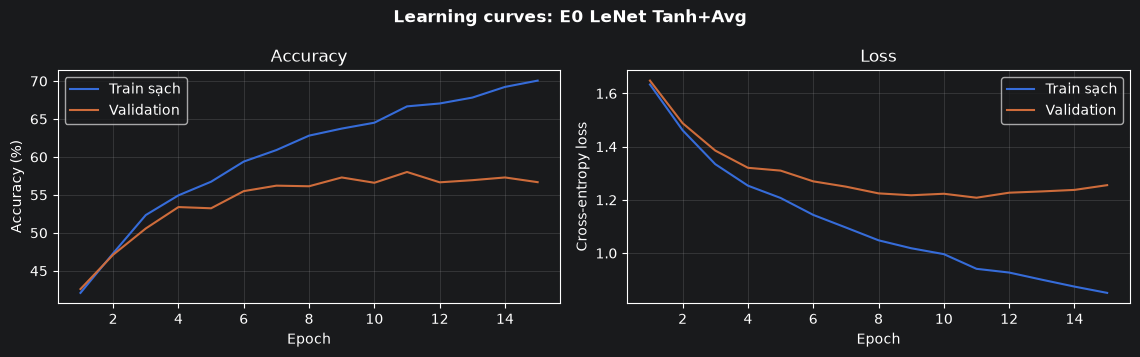


=== E1 LeNet ReLU+Max [TỪ CACHE: E1_LeNet_ReLU_Max_ep15_full_wd0_aug0.pkl] ===
CHECKPOINT: epoch 14 | train_acc=73.66% | val_acc=63.74% | val_loss=1.0685 | gap=+9.92%


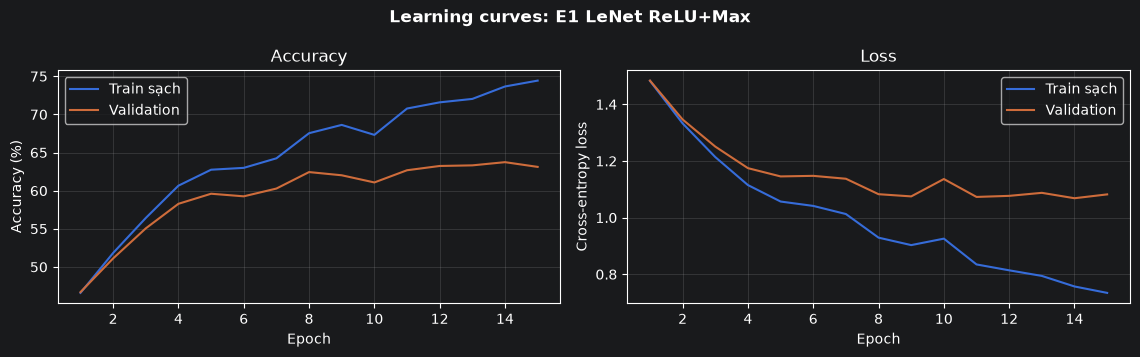


=== E2 E1+Dropout+WD [TỪ CACHE: E2_E1_Dropout_WD_ep15_full_wd0.01_aug0.pkl] ===
CHECKPOINT: epoch 14 | train_acc=69.09% | val_acc=62.16% | val_loss=1.0690 | gap=+6.93%


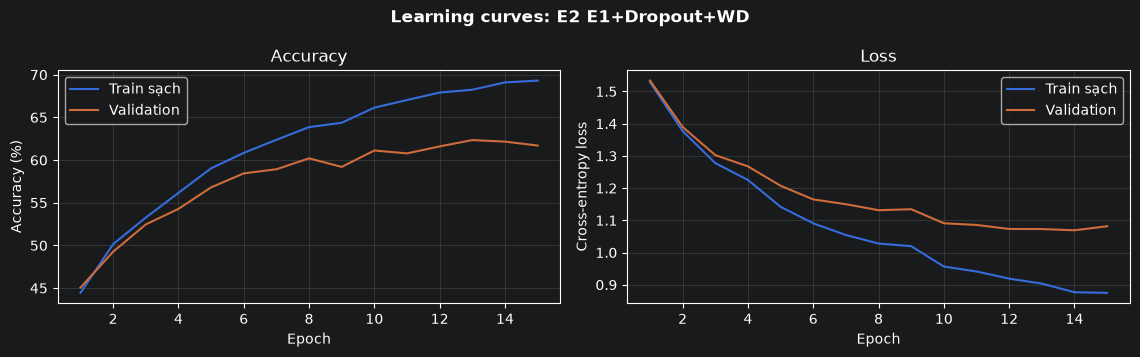


=== E3 E2+Aug [TỪ CACHE: E3_E2_Aug_ep15_full_wd0.01_aug1.pkl] ===
CHECKPOINT: epoch 15 | train_acc=62.92% | val_acc=61.84% | val_loss=1.0824 | gap=+1.08%


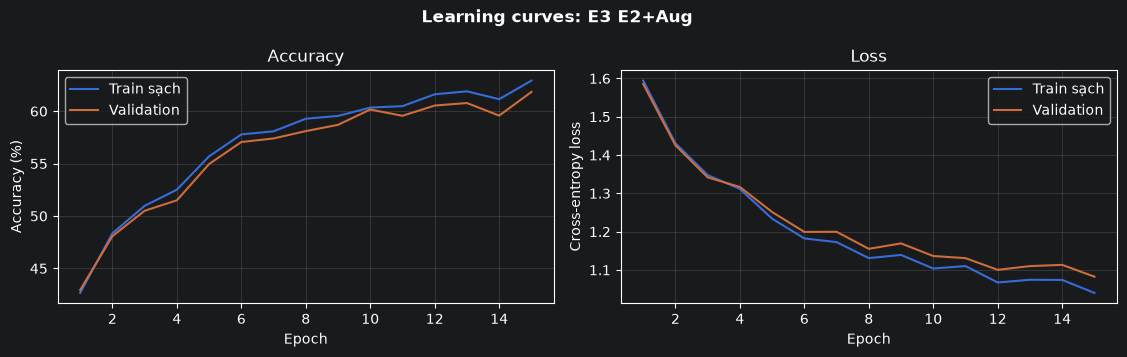


=== E4 E3+BatchNorm [TỪ CACHE: E4_E3_BatchNorm_ep15_full_wd0.01_aug1.pkl] ===
CHECKPOINT: epoch 15 | train_acc=63.28% | val_acc=61.76% | val_loss=1.0635 | gap=+1.52%


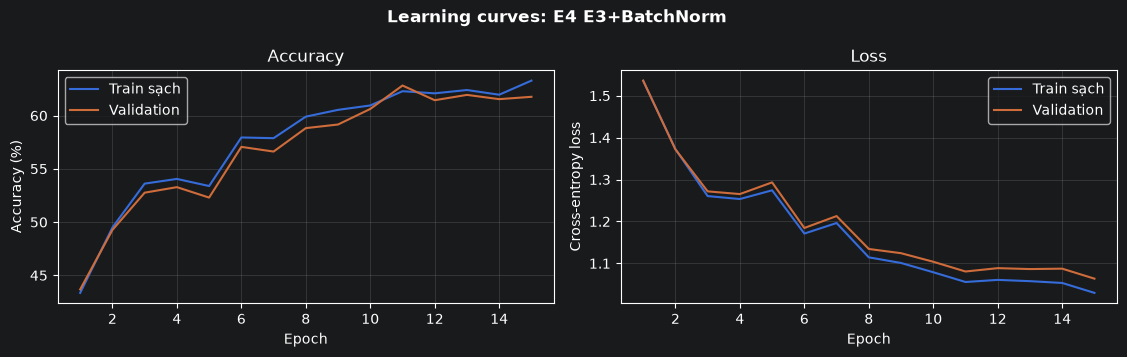


=== M1 VGG-tiny [TỪ CACHE: M1_VGG-tiny_ep15_full_wd0_aug0.pkl] ===
CHECKPOINT: epoch 15 | train_acc=87.29% | val_acc=77.86% | val_loss=0.6696 | gap=+9.43%


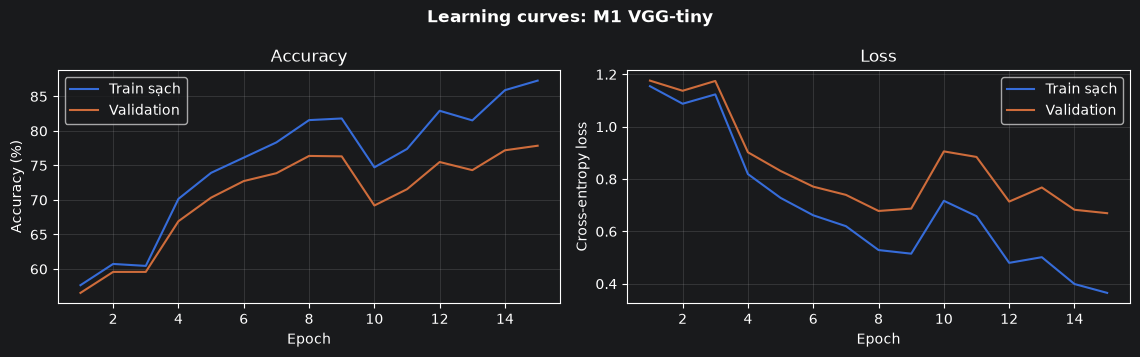


=== M2 Inception-tiny [TỪ CACHE: M2_Inception-tiny_ep15_full_wd0_aug0.pkl] ===
CHECKPOINT: epoch 15 | train_acc=77.91% | val_acc=73.30% | val_loss=0.7790 | gap=+4.61%


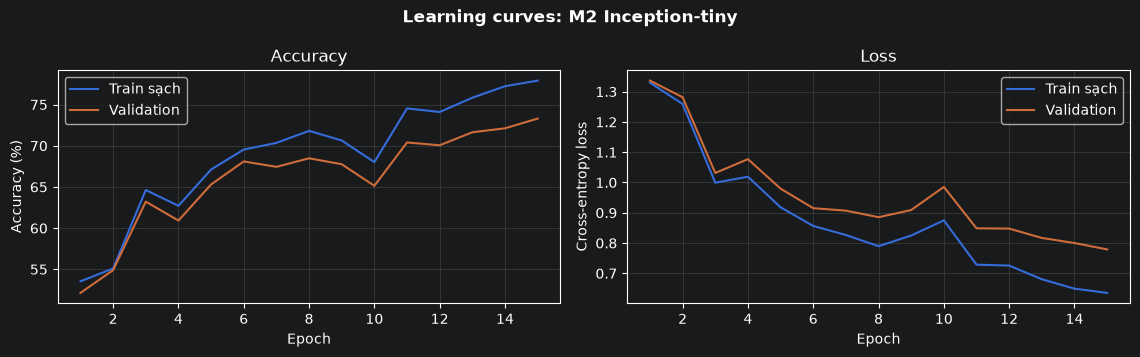


=== M3 ResNet-tiny [TỪ CACHE: M3_ResNet-tiny_ep15_full_wd0_aug0.pkl] ===
CHECKPOINT: epoch 10 | train_acc=89.09% | val_acc=78.00% | val_loss=0.6750 | gap=+11.09%


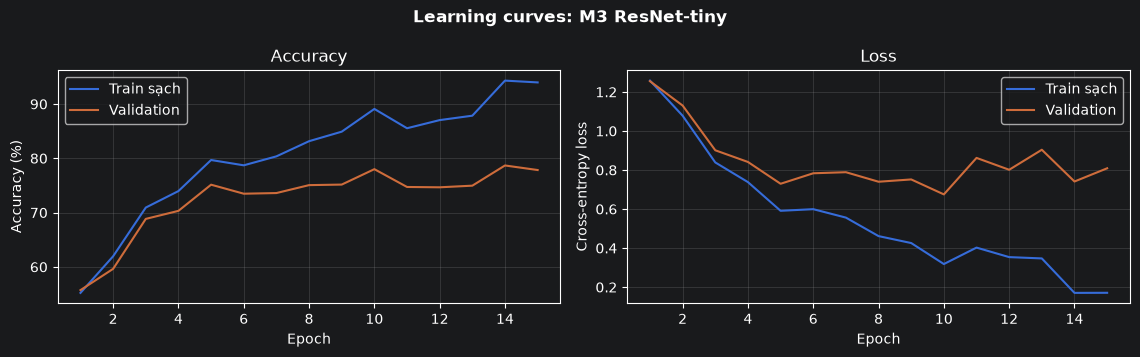


=== BẢNG TỔNG HỢP VALIDATION ===
            model  params  best_epoch  train_acc  val_acc  val_loss      gap  seconds
      M1 VGG-tiny   77114          15   0.872925   0.7786  0.669559 0.094325  1340.67
   M3 ResNet-tiny  170586          10   0.890925   0.7800  0.675042 0.110925  1394.88
M2 Inception-tiny   27850          15   0.779100   0.7330  0.778991 0.046100  2157.72
  E4 E3+BatchNorm   62050          15   0.632800   0.6176  1.063462 0.015200  1066.51
E1 LeNet ReLU+Max   62006          14   0.736625   0.6374  1.068488 0.099225   640.43
 E2 E1+Dropout+WD   62006          14   0.690950   0.6216  1.069020 0.069350   610.31
        E3 E2+Aug   62006          15   0.629175   0.6184  1.082373 0.010775   721.28
E0 LeNet Tanh+Avg   62006          11   0.666650   0.5802  1.208118 0.086450   604.83


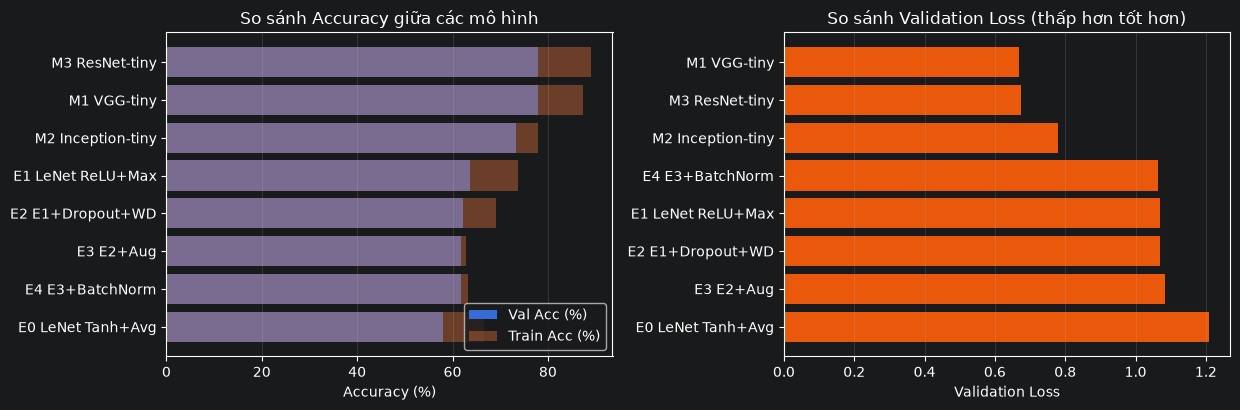

In [16]:
experiments = [
    ("E0 LeNet Tanh+Avg", lambda: LeNet(activation="tanh", pool="avg"), False, 0.0),
    ("E1 LeNet ReLU+Max", lambda: LeNet(activation="relu", pool="max"), False, 0.0),
    ("E2 E1+Dropout+WD", lambda: LeNet(activation="relu", pool="max", dropout=0.3), False, 1e-2),
    ("E3 E2+Aug", lambda: LeNet(activation="relu", pool="max", dropout=0.3), True, 1e-2),
    ("E4 E3+BatchNorm", lambda: LeNet(activation="relu", pool="max", batchnorm=True, dropout=0.3), True, 1e-2),
    ("M1 VGG-tiny", VGGTiny, False, 0.0),
    ("M2 Inception-tiny", InceptionTiny, False, 0.0),
    ("M3 ResNet-tiny", ResNetTiny, False, 0.0),
]

results_rows = []
model_factories = {}
bundles = {}

for exp_name, factory, use_aug, wd in experiments:
    model_factories[exp_name] = factory
    b = run_experiment(exp_name, factory, loaders, use_aug=use_aug, wd=wd, show_inline=SHOW_PLOTS_INLINE)
    bundles[exp_name] = b
    results_rows.append(b["row"])

df_res = pd.DataFrame(results_rows).sort_values(by=["val_loss", "val_acc"], ascending=[True, False])
print("\n=== BẢNG TỔNG HỢP VALIDATION ===")
print(df_res.to_string(index=False))
df_res.to_csv(OUTPUT_ROOT / "validation_summary.csv", index=False)
plot_summary_comparison(df_res, show_inline=SHOW_PLOTS_INLINE)

## Cell 7: Đánh giá trên tập Test, ma trận nhầm lẫn, phân tích lỗi & xuất file nộp bài
Đánh giá mô hình tốt nhất (`M1 VGG-tiny`) trên tập Test, vẽ Confusion Matrix, trực quan hóa Top-6 ca dự đoán sai tự tin nhất và xuất `submission.csv` (nếu có dữ liệu test Kaggle).


=== ĐÁNH GIÁ CUỐI TRÊN TEST (M1 VGG-tiny) ===
Test loss: 0.6894 | Test acc: 77.44%
              precision    recall  f1-score   support

    airplane       0.79      0.78      0.79       500
  automobile       0.90      0.88      0.89       500
        bird       0.74      0.67      0.70       500
         cat       0.67      0.55      0.60       500
        deer       0.68      0.81      0.74       500
         dog       0.71      0.67      0.69       500
        frog       0.66      0.90      0.76       500
       horse       0.89      0.74      0.81       500
        ship       0.86      0.88      0.87       500
       truck       0.91      0.86      0.88       500

    accuracy                           0.77      5000
   macro avg       0.78      0.77      0.77      5000
weighted avg       0.78      0.77      0.77      5000



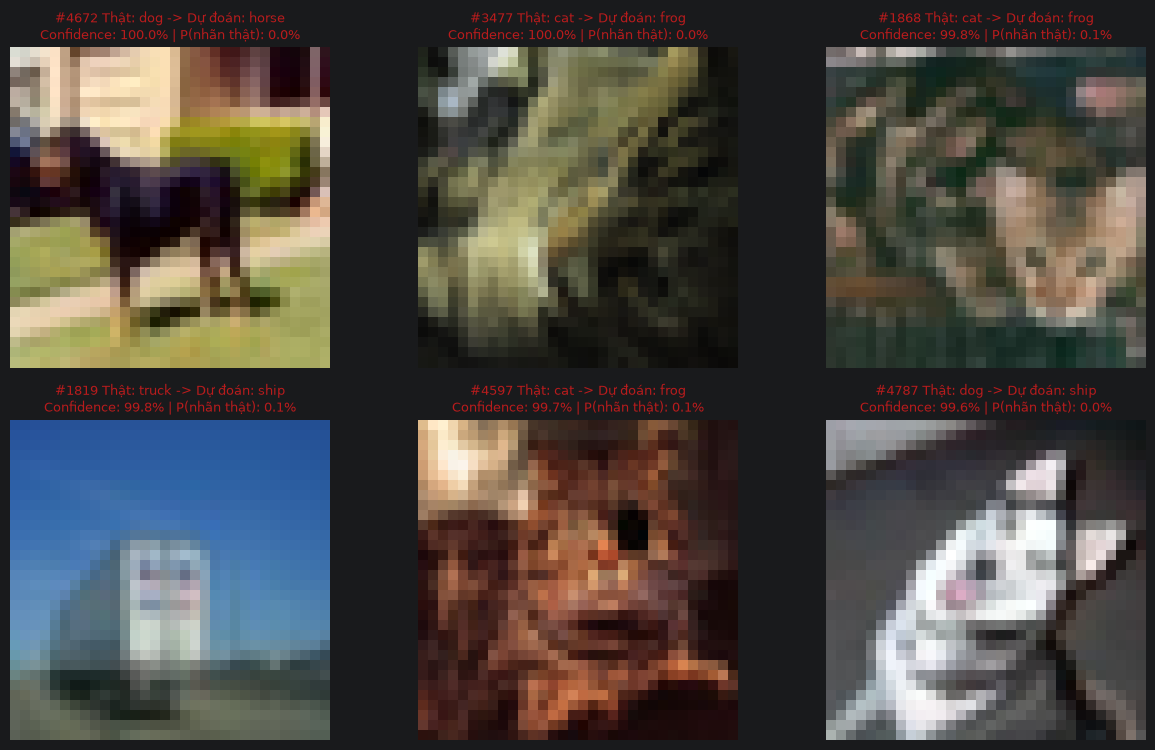

Đã lưu ảnh phân tích ca dự đoán sai vào: D:\WelcomeScreen\outputs\script1\plots\top_errors_M1_VGG-tiny.png


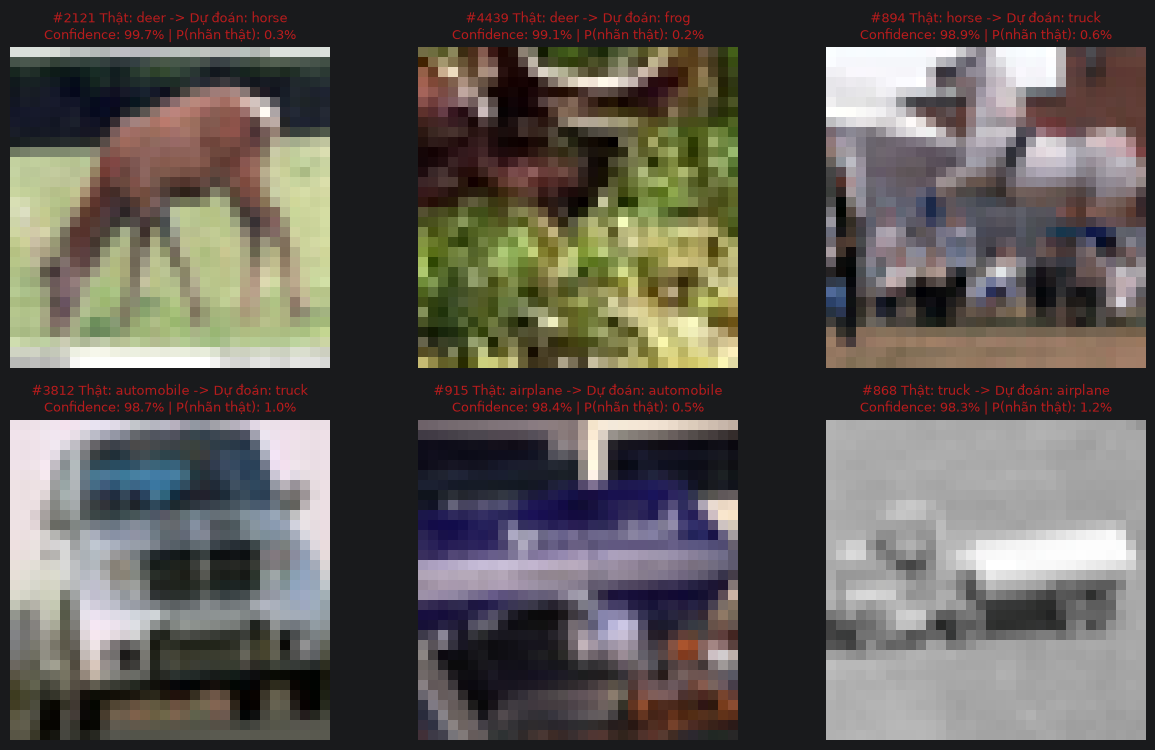

Đã lưu ảnh phân tích ca dự đoán sai vào: D:\WelcomeScreen\outputs\script1\plots\top_errors_M2_Inception-tiny.png


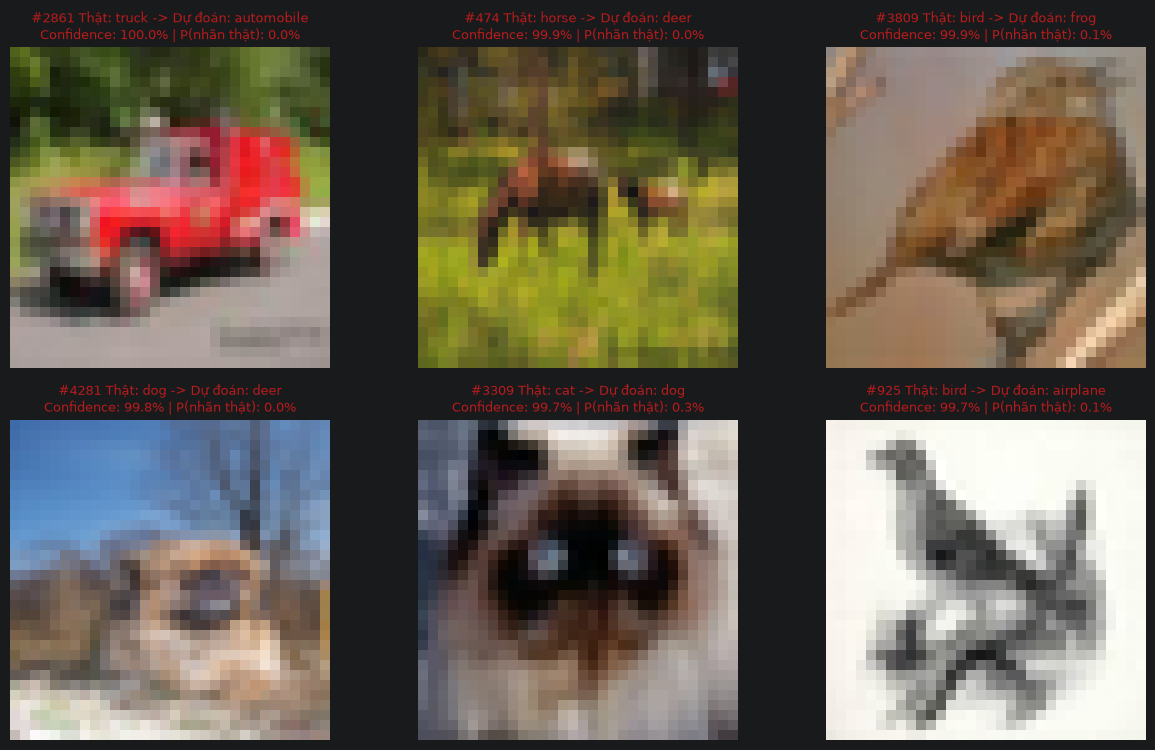

Đã lưu ảnh phân tích ca dự đoán sai vào: D:\WelcomeScreen\outputs\script1\plots\top_errors_M3_ResNet-tiny.png
Bỏ qua xuất submission vì thư mục D:\WelcomeScreen\data\test mới có 0 ảnh (chưa đầy đủ)

Hoàn tất! Toàn bộ kết quả nộp bài (15 epochs) của 'script1' đã lưu tại: D:\WelcomeScreen\outputs\script1


In [17]:
best_name = df_res.iloc[0]["model"]
best_model = model_factories[best_name]().to(DEVICE)
best_model.load_state_dict({k: v.to(DEVICE) for k, v in bundles[best_name]["state_dict"].items()})

test_out = test_model(best_model, test_loader, criterion, DEVICE, CIFAR10_CLASSES)
print(f"\n=== ĐÁNH GIÁ CUỐI TRÊN TEST ({best_name}) ===")
print(f"Test loss: {test_out['loss']:.4f} | Test acc: {test_out['accuracy']:.2%}")
print(test_out["classification_report"])
plot_confusion_matrix(
    test_out["confusion_matrix"],
    CIFAR10_CLASSES,
    f"Confusion Matrix trên tập Test ({best_name} - Acc: {test_out['accuracy']:.2%})",
    PLOT_DIR / f"confusion_matrix_{safe_filename(best_name)}.png",
    show_inline=SHOW_PLOTS_INLINE,
)

error_models = [m for m in ["M1 VGG-tiny", "M2 Inception-tiny", "M3 ResNet-tiny"] if m in bundles]
if best_name not in error_models:
    error_models.append(best_name)

for m_name in error_models:
    m_inst = model_factories[m_name]().to(DEVICE)
    m_inst.load_state_dict({k: v.to(DEVICE) for k, v in bundles[m_name]["state_dict"].items()})
    plot_top_misclassified(
        m_inst,
        val_ds,
        CIFAR10_CLASSES,
        DEVICE,
        PLOT_DIR / f"top_errors_{safe_filename(m_name)}.png",
        mean=MEAN,
        std=STD,
        top_k=6,
        show_inline=SHOW_PLOTS_INLINE,
    )

summary_path = OUTPUT_ROOT / f"summary_{safe_filename(best_name)}.txt"
with open(summary_path, "w", encoding="utf-8") as f:
    f.write("=== BẢNG TỔNG HỢP VALIDATION ===\n")
    f.write(df_res.to_string(index=False) + "\n\n")
    f.write(f"=== ĐÁNH GIÁ CUỐI TRÊN TEST ({best_name}) ===\n")
    f.write(f"Test loss: {test_out['loss']:.4f} | Test acc: {test_out['accuracy']:.2%}\n")
    f.write(test_out["classification_report"] + "\n")
    f.write("=== CONFUSION MATRIX (TEST) ===\n")
    f.write(np.array2string(test_out["confusion_matrix"]) + "\n")

export_kaggle_submission(
    best_model, test_img_dir, eval_transform, OUTPUT_ROOT / "submission.csv", num_workers=num_workers
)
print(f"\nHoàn tất! Toàn bộ kết quả nộp bài (15 epochs) của '{RUN_TAG}' đã lưu tại: {OUTPUT_ROOT}")

## Cell 8: Nhận xét & Phân tích kết quả thí nghiệm

1. **So sánh các biến thể LeNet (`E0` $\rightarrow$ `E4`):**
   * **`E0 (Tanh + AvgPool)` $\rightarrow$ `E1 (ReLU + MaxPool)`:** Chuyển sang `ReLU` và `MaxPool` giúp cải thiện rõ rệt độ chính xác trên tập Validation từ **58.02%** lên **63.74%** (`val_loss` giảm từ `1.2081` xuống `1.0685`), do khắc phục hiện tượng bão hòa gradient của hàm `Tanh` và giữ lại đặc trưng nổi bật tốt hơn.
   * **`E2 (E1 + Dropout 0.3 + Weight Decay 1e-2)`:** Giảm khoảng cách overfitting (`gap`) từ **+9.92%** xuống **+6.93%** trong khi vẫn giữ `val_loss` tương đương (`1.0690`).
   * **`E3 (E2 + Augmentation)` & `E4 (E3 + BatchNorm)`:** Khi kết hợp Augmentation và BatchNorm với dung lượng mạng nhỏ của LeNet (`62k` tham số) trong `15 epochs`, mức độ underfitting nhẹ khiến `train_acc` giảm xuống ~63%, nhưng `gap` giảm mạnh chỉ còn **+1.08% – +1.52%** và `E4` đạt `val_loss` thấp nhất trong nhóm LeNet (**1.0635**).

2. **So sánh các kiến trúc hiện đại thu gọn (`M1`, `M2`, `M3`):**
   * **`M1 VGG-tiny` (`77,114` tham số):** Đạt `val_loss` thấp nhất toàn bộ thí nghiệm (**0.6696**), `val_acc = 77.86%` và đạt **77.44%** trên tập Test (`Test loss = 0.6894`), được chọn làm mô hình tốt nhất để đánh giá cuối.
   * **`M3 ResNet-tiny` (`170,586` tham số):** Đạt `val_acc` cao nhất (**78.00%** ở epoch 10) nhờ kết nối tắt (*skip connection*), tuy nhiên bắt đầu overfit nhẹ sau epoch 10 (`gap = +11.09%`, `val_loss = 0.6750`). Nếu bổ sung Data Augmentation + Weight Decay cho `M3`, hiệu năng sẽ còn vượt trội hơn.
   * **`M2 Inception-tiny` (`27,850` tham số):** Với số lượng tham số ít nhất (chỉ bằng ~36% `VGGTiny` và ~16% `ResNetTiny`), mô hình vẫn đạt **73.30%** `val_acc` và mức độ tổng quát hóa rất ổn định (`gap = +4.61%`).

3. **Phân tích lỗi theo từng lớp trên tập Test (`M1 VGG-tiny`):**
   * Các lớp phương tiện có đường nét đặc trưng rõ ràng đạt F1-score rất cao: **`automobile` (0.89)**, **`truck` (0.88)**, **`ship` (0.87)**.
   * Nhóm động vật có hình dáng và bối cảnh tương đồng dễ nhầm lẫn với nhau nhất, đặc biệt là **`cat` (F1 = 0.60, recall = 0.55)** và **`dog` (F1 = 0.69)**.